# LiquidGraph validation

This notebook tests the claims made about `aethelnet.liquid_graph.LiquidGraph` against the code
and against standard baselines. Every claim gets an experiment that could have **confirmed or
refuted** it. The source of truth is `research/lgnn_validation.py` (Jupytext percent format);
the `.ipynb` is generated from it with outputs.

Run it with:

```bash
pip install -e ".[dev]" -r research/requirements.txt
jupytext --to ipynb research/lgnn_validation.py
jupyter nbconvert --to notebook --execute --inplace research/lgnn_validation.ipynb
```

## Summary

| # | Claim | Test | Verdict |
|---|---|---|---|
| 1 | Node states follow a nonlinear "liquid" ODE ($\tanh$, $\tau_i$, inputs) | `evolve_topology` vs. the linear closed form | ❌ **Refuted.** Exactly a fixed linear graph filter (max error ~3·10⁻⁷). Its long-time limit is Personalized PageRank / APPNP propagation with teleport ≈ 0.59 |
| 2 | The MLP and attention modules shape the dynamics | Same input, different module weights | ❌ **Refuted.** Identical output; ~4.7 M parameters are never used |
| 3 | "Activation energy" is a meaningful signal | Energy distribution after evolution | ❌ Always exactly 1.0 (states are normalised) |
| 4 | O(1) RAM thanks to sharding | Peak memory vs. $N$ | ❌ Grows ~$N^2$; autograd bookkeeping alone costs ~11× (fixed in a separate PR) |
| 5 | Sharding still finds the graph's edges | Discovered edges vs. theory | ⚠️ Only $S^2/N^2$ ≈ 6 % per call; about half are still missing after 10 calls |
| 6 | Edges form by Hebbian co-firing | Reported edges vs. a cosine threshold | ❌ Exactly a cosine-similarity threshold. ✅ But the new edges are 100 % class-consistent |
| 7 | The graph dynamics add useful structure | Benchmark vs. raw features and APPNP across homophily | ⚠️ Helps on homophilous graphs (purity@10 0.67 → 0.80 at $h$ = 0.9), hurts on heterophilous ones, and is weaker than standard APPNP when the graph is informative |
| 8 | The elastic tether keeps concepts distinct | Long evolution with / without tether | ✅ **Confirmed** for distinctness. ⚠️ It also caps the class structure the graph can add (0.86 vs. 0.99): a trade-off, not a free win |

**Bottom line:** `LiquidGraph` is a stable, cheap and well-behaved *graph feature smoother*: mathematically a
known method (heat-kernel diffusion converging to PPR), with a sensible anchoring term and a useful
similarity-based edge rule. The "liquid", "Hebbian" and "O(1)" labels describe something the code does not do
(yet). Measurements were taken on Windows, CPU-only PyTorch; absolute memory/time numbers vary by machine,
the scaling and the comparisons do not.

In [1]:
import json
import logging
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

REPO = Path.cwd().parent if Path.cwd().name == "research" else Path.cwd()
sys.path.insert(0, str(REPO))
from aethelnet.liquid_graph import LiquidGraph  # noqa: E402

logging.disable(logging.CRITICAL)  # LiquidGraph logs per node; keep the notebook readable
torch.manual_seed(0)
print("torch", torch.__version__, "| repo", REPO.name)

torch 2.14.1+cpu | repo aethelnet-core


### Helpers

Graphs are built through the public `LiquidGraph` API (`add_node`, `nx_graph.add_edge`,
`evolve_topology`), exactly as `aethelnet-node` uses it.
`resonance_threshold > 1` switches off Hebbian edge growth where an experiment is only about
the node dynamics, so the Python edge loops don't dominate runtime.

In [2]:
def build_graph(X, edges, *, tether=0.5, threshold=1.01, shard_size=10000, seed=0):
    torch.manual_seed(seed)  # only affects the initialisation of the (unused) sub-modules
    g = LiquidGraph(hidden_dim=X.shape[1], resonance_threshold=threshold,
                    tether_strength=tether, shard_size=shard_size)
    for i in range(X.shape[0]):
        g.add_node(f"n{i}", X[i])
    for u, v in edges:
        g.nx_graph.add_edge(f"n{u}", f"n{v}", weight=1.0)
    return g


def node_states(g, n):
    return torch.stack([g.get_node_embedding(f"n{i}") for i in range(n)])


def adjacency(n, edges):
    A = torch.zeros(n, n)
    for u, v in edges:
        A[u, v] = A[v, u] = 1.0
    return A


def row_normalize(A):
    return A / A.sum(1, keepdim=True).clamp(min=1.0)  # same as LiquidGraph.forward


def lgnn_closed_form(X0, A, T, alpha=0.35, lam=0.5):
    """Exact solution of dx/dt = alpha (P - I) x - lam (x - x0), x(0) = x0, then L2-normalised."""
    n = A.shape[0]
    I = torch.eye(n)
    M = alpha * (row_normalize(A) - I) - lam * I
    E = torch.matrix_exp(M * T)
    Xt = E @ X0 if lam == 0 else E @ X0 + torch.linalg.solve(M, (E - I) @ (lam * X0))
    return F.normalize(Xt, dim=1)


def ppr_propagate(X0, A, teleport):
    """Personalized-PageRank feature propagation (the APPNP limit): teleport * (I - (1-teleport) P)^-1 X0."""
    n = A.shape[0]
    Z = teleport * torch.linalg.solve(torch.eye(n) - (1 - teleport) * row_normalize(A), X0)
    return F.normalize(Z, dim=1)


def csbm(n=900, C=3, d=64, k=10, h=0.8, noise=3.5, seed=0):
    """Contextual stochastic block model: class-dependent features + a graph with edge homophily h."""
    rng = np.random.default_rng(seed)
    y = rng.permutation(np.arange(n) % C)
    mu = np.linalg.qr(rng.normal(size=(d, C)))[0].T          # C orthonormal class directions
    X = mu[y] + rng.normal(size=(n, d)) * noise / np.sqrt(d)  # noise norm ~ `noise`
    iu = np.triu_indices(n, 1)
    same = y[iu[0]] == y[iu[1]]
    n_in = n / C
    p = np.where(same, h * k / (n_in - 1), (1 - h) * k / (n - n_in))
    keep = rng.random(len(same)) < p
    edges = list(zip(iu[0][keep].tolist(), iu[1][keep].tolist()))
    return F.normalize(torch.tensor(X, dtype=torch.float32), dim=1), torch.tensor(y), edges


def purity_at_k(X, y, k=10):
    """Fraction of each node's k nearest neighbours (cosine) that share its class."""
    Xn = F.normalize(X, dim=1)
    S = Xn @ Xn.T
    S.fill_diagonal_(-2.0)
    idx = S.topk(k, dim=1).indices
    return float((y[idx] == y[:, None]).float().mean())


def kmeans_ari(X, y, C=3, seed=0):
    pred = KMeans(n_clusters=C, n_init=10, random_state=seed).fit_predict(F.normalize(X, dim=1).numpy())
    return float(adjusted_rand_score(y.numpy(), pred))


def mean_pairwise_cos(X):
    Xn = F.normalize(X, dim=1)
    n = Xn.shape[0]
    return float(((Xn @ Xn.T).sum() - n) / (n * (n - 1)))


def edge_homophily(edges, y):
    return float(np.mean([int(y[u]) == int(y[v]) for u, v in edges])) if edges else float("nan")

### Chart style

Three series at most per chart, colours from a palette validated for colour-vision deficiency
(all pairs), distinct marker shapes as a second channel, and direct labels plus a table for every
chart so nothing depends on colour alone.

In [3]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = [("#2a78d6", "o"), ("#eb6834", "s"), ("#1baf7a", "^")]
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"], "font.size": 9.5})


def new_ax(title, xlabel, ylabel):
    fig, ax = plt.subplots(figsize=(6.6, 3.7), dpi=110)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(colors=AXIS, labelcolor=INK2)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel(xlabel, color=INK2)
    ax.set_ylabel(ylabel, color=INK2)
    return fig, ax


def plot_series(ax, x, y, slot, label, linestyle="-", end_label=True, dy=0):
    color, marker = SERIES[slot]
    ax.plot(x, y, color=color, linewidth=2, linestyle=linestyle, marker=marker, markersize=6,
            markeredgecolor=SURFACE, markeredgewidth=1.2, label=label)
    if end_label:
        ax.annotate(label, (x[-1], y[-1]), xytext=(7, dy), textcoords="offset points",
                    va="center", color=INK2, fontsize=8.5)


def finish(fig, ax, legend_loc="best"):
    ax.legend(frameon=False, labelcolor=INK2, fontsize=8.5, loc=legend_loc)
    fig.tight_layout()
    plt.show()

## 1 · Dynamics: nonlinear "liquid" ODE, or a fixed linear filter?

**Claim (README):** node states follow
$\frac{dh_i}{dt} = -\tau_i h_i + \tanh\big(\sum_j W_{ij}(t) h_j + I_i(t)\big)$.

**What `forward` computes:** $\dot x = 0.35\,(D^{-1}A - I)\,x - \lambda\,(x - x_0)$ with
$\lambda$ = `tether_strength` = 0.5, plus a clamp that is inactive for unit-norm states.
If that is all there is, the ODE has the closed-form solution

$$x(T) = e^{MT}x_0 + M^{-1}\big(e^{MT} - I\big)\,\lambda x_0, \qquad M = 0.35\,(P - I) - \lambda I,\ P = D^{-1}A$$

**Test:** run `evolve_topology` and compare with this formula. A nonlinear system would not match.

In [4]:
X, y, E = csbm(n=600, h=0.8, seed=1)
A = adjacency(len(y), E)
rows = []
for T in (0.5, 1.0, 3.0):
    g = build_graph(X, E)
    g.evolve_topology(compute_time=T)
    err = float((node_states(g, len(y)) - lgnn_closed_form(X, A, T)).abs().max())
    rows.append((T, err))
    print(f"compute_time={T:<4}  max |evolve_topology - closed form| = {err:.1e}")
assert max(e for _, e in rows) < 1e-4

compute_time=0.5   max |evolve_topology - closed form| = 3.3e-07


compute_time=1.0   max |evolve_topology - closed form| = 2.7e-07


compute_time=3.0   max |evolve_topology - closed form| = 3.6e-07


The solver output matches the linear closed form to float32 precision (the residual is the RK4
step error). So the dynamics are a **fixed linear graph filter**: no $\tanh$, no per-node $\tau_i$,
no input $I(t)$, and no learned $W_{ij}$.

**Corollary — the long-time limit is Personalized PageRank.** Setting $\dot x = 0$ gives
$x^* = \gamma\,(I - (1-\gamma)P)^{-1}x_0$ with teleport $\gamma = \lambda/(\lambda + 0.35) \approx 0.588$,
which is exactly PPR/APPNP feature propagation
([Gasteiger et al., ICLR 2019](https://arxiv.org/abs/1810.05997)). For finite $T$ the filter is a
heat-kernel-style diffusion ([Gasteiger et al., NeurIPS 2019](https://arxiv.org/abs/1911.05485)).

In [5]:
gamma = 0.5 / (0.5 + 0.35)
g = build_graph(X, E)
g.evolve_topology(compute_time=60.0)
err = float((node_states(g, len(y)) - ppr_propagate(X, A, gamma)).abs().max())
print(f"teleport gamma = {gamma:.3f}; max |evolve_topology(T=60) - PPR| = {err:.1e}")
assert err < 1e-3

teleport gamma = 0.588; max |evolve_topology(T=60) - PPR| = 4.2e-07


## 2 · Learned modules: do `flow_dynamics` and `resonance_aligner` take part?

`LiquidGraph.__init__` builds an MLP (`flow_dynamics`) and an 8-head attention layer
(`resonance_aligner`). **Test:** count their parameters, then evolve two graphs that are identical
except for the random initialisation of these modules. If the modules mattered, results would differ.

In [6]:
def module_params(g):
    return sum(p.numel() for m in (g.flow_dynamics, g.resonance_aligner) for p in m.parameters())

print(f"parameters in the two modules at the default hidden_dim=768: {module_params(LiquidGraph()):,}")
g1, g2 = build_graph(X, E, seed=1), build_graph(X, E, seed=2)
w_diff = float((g1.flow_dynamics[0].weight - g2.flow_dynamics[0].weight).abs().max().detach())
g1.evolve_topology(1.0)
g2.evolve_topology(1.0)
out_diff = float((node_states(g1, len(y)) - node_states(g2, len(y))).abs().max())
print(f"module weights differ by up to {w_diff:.3f}; evolved states differ by {out_diff:.1e}")
assert out_diff == 0.0

parameters in the two modules at the default hidden_dim=768: 4,723,968


module weights differ by up to 0.247; evolved states differ by 0.0e+00


The modules never touch the dynamics (they are only saved and loaded with checkpoints).
At the default size that is ~4.7 M parameters of dead weight in memory and in every snapshot.

## 3 · "Activation energy" as a signal

`get_node_energy()` returns the L2 norm of a node's state and is exposed as a metric. But
`add_node` and `evolve_topology` both L2-normalise states. **Test:** distribution of energies
after evolution.

In [7]:
energies = np.array([g1.get_node_energy(f"n{i}") for i in range(len(y))])
print(f"energy over {len(energies)} nodes: min {energies.min():.6f}, max {energies.max():.6f}")

energy over 600 nodes: min 1.000000, max 1.000000


Every node has energy 1.0 by construction, so the metric carries no information.

## 4 · Memory: "O(1) RAM via Stochastic Neighborhood Sharding"?

`evolve_topology` converts the graph with `nx.to_scipy_sparse_array(...)` and then calls
`.todense()`, i.e. it materialises an $N \times N$ adjacency before any sharding happens.
**Test:** measure peak memory and wall time of one `evolve_topology` call for growing $N$
(random graph, average degree 10, `hidden_dim=64`), each in a fresh process. The second series
forces the sharded code path (`shard_size = N/4`); the third wraps the unchanged call in
`torch.no_grad()` (see below for why).

In [8]:
SCALING_CODE = r"""
import json, logging, sys, time
import networkx as nx, psutil, torch
logging.disable(logging.CRITICAL)
sys.path.insert(0, sys.argv[1])
from aethelnet.liquid_graph import LiquidGraph
N, shard, no_grad = int(sys.argv[2]), int(sys.argv[3]), sys.argv[4] == "1"
torch.manual_seed(0)
X = torch.nn.functional.normalize(torch.randn(N, 64), dim=1)
g = LiquidGraph(hidden_dim=64, resonance_threshold=1.01, shard_size=shard)
for i in range(N):
    g.add_node(f"n{i}", X[i])
for u, v in nx.gnm_random_graph(N, 5 * N, seed=1).edges():
    g.nx_graph.add_edge(f"n{u}", f"n{v}", weight=1.0)
proc = psutil.Process()
def peak():
    info = proc.memory_info()
    if hasattr(info, "peak_wset"):          # Windows
        return info.peak_wset
    import resource                          # Linux/macOS (ru_maxrss in KiB on Linux)
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss * 1024
rss_before = proc.memory_info().rss
t0 = time.perf_counter()
if no_grad:
    with torch.no_grad():
        g.evolve_topology(compute_time=1.0)
else:
    g.evolve_topology(compute_time=1.0)
print(json.dumps({"N": N, "seconds": time.perf_counter() - t0, "peak_mb": (peak() - rss_before) / 2**20}))
"""

def measure(N, shard, no_grad=False):
    out = subprocess.run([sys.executable, "-c", SCALING_CODE, str(REPO), str(N), str(shard), "1" if no_grad else "0"],
                         capture_output=True, text=True, check=True)
    return json.loads(out.stdout.strip().splitlines()[-1])

Ns = [1000, 2000, 4000, 8000]
full = [measure(N, 10_000) for N in Ns]
sharded = [measure(N, N // 4) for N in Ns]
nograd = [measure(N, 10_000, no_grad=True) for N in Ns]
print(f"{'N':>6} | {'as is: MB':>9} {'s':>6} | {'sharded: MB':>11} {'s':>6} | {'no_grad: MB':>11} {'s':>6}")
for f_, s_, n_ in zip(full, sharded, nograd):
    print(f"{f_['N']:>6} | {f_['peak_mb']:>9.0f} {f_['seconds']:>6.2f} | {s_['peak_mb']:>11.0f} {s_['seconds']:>6.2f} | "
          f"{n_['peak_mb']:>11.0f} {n_['seconds']:>6.2f}")

def loglog_slope(xs, ys):
    return float(np.polyfit(np.log(xs), np.log(ys), 1)[0])

for name, rows_ in (("as is", full), ("sharded", sharded), ("no_grad", nograd)):
    print(f"memory ~ N^{loglog_slope(Ns[1:], [r['peak_mb'] for r in rows_[1:]]):.2f} ({name})")
print(f"at N={Ns[-1]}: as is / no_grad = {full[-1]['peak_mb'] / nograd[-1]['peak_mb']:.1f}x")

     N | as is: MB      s | sharded: MB      s | no_grad: MB      s
  1000 |       211   0.62 |         197   0.33 |          21   0.47
  2000 |       755   1.23 |         706   0.63 |          75   0.98
  4000 |      2845   2.61 |        2660   1.49 |         258   2.21
  8000 |     11081   9.93 |       10340   5.71 |        1021   6.73
memory ~ N^1.94 (as is)
memory ~ N^1.94 (sharded)
memory ~ N^1.88 (no_grad)
at N=8000: as is / no_grad = 10.9x


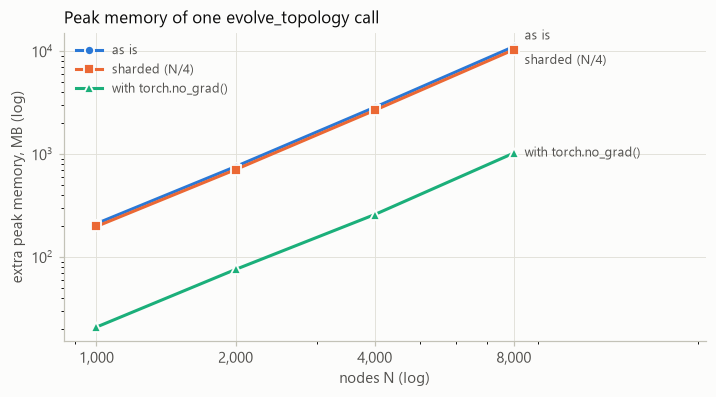

In [9]:
fig, ax = new_ax("Peak memory of one evolve_topology call", "nodes N (log)", "extra peak memory, MB (log)")
ax.set_xscale("log")
ax.set_yscale("log")
plot_series(ax, Ns, [r["peak_mb"] for r in full], 0, "as is", dy=7)
plot_series(ax, Ns, [r["peak_mb"] for r in sharded], 1, "sharded (N/4)", dy=-7)
plot_series(ax, Ns, [r["peak_mb"] for r in nograd], 2, "with torch.no_grad()")
ax.set_xticks(Ns, [f"{N:,}" for N in Ns])
ax.set_xlim(Ns[0] * 0.85, Ns[-1] * 2.6)
finish(fig, ax, legend_loc="upper left")

Memory grows with $N^2$ in every variant, so "O(1) RAM" is not supported. Two separate causes:

1. **Autograd (the big one).** Node states are `nn.Parameter`s, so `odeint` records the whole
   integration for a backward pass that never happens. Each of the 40 RK4 evaluations keeps its
   own $N \times N$ normalised adjacency alive. Running the unchanged call under `torch.no_grad()`
   cuts peak memory by an order of magnitude with identical results.
2. **Dense adjacency.** Sharding only bounds the similarity matrix; the adjacency is densified
   (float64 during conversion, then float32) before sharding. A sparse adjacency would make the
   ODE part scale with the number of edges instead.

## 5 · Sharding coverage: which edges can be discovered?

Above `shard_size`, each `evolve_topology` call compares only a random subset of $S$ nodes.
A given pair can only get a Hebbian edge if both nodes land in the same shard, which happens
with probability $p = \frac{S(S-1)}{N(N-1)}$ per call. **Test:** 100 tight clusters of 20 nodes
(every within-cluster pair qualifies), $N = 2000$, $S = 500$, no initial edges; track how many
qualifying pairs have an edge after each call.

In [10]:
rng = np.random.default_rng(3)
centers = rng.normal(size=(100, 64))
Xc = np.repeat(centers, 20, axis=0) + rng.normal(size=(2000, 64)) * 0.3
Xc = F.normalize(torch.tensor(Xc, dtype=torch.float32), dim=1)
cluster = np.repeat(np.arange(100), 20)
qualifying = {(i, j) for i in range(2000) for j in range(i + 1, min(2000, (i // 20 + 1) * 20))}
S_, N_ = 500, 2000
p = S_ * (S_ - 1) / (N_ * (N_ - 1))

torch.manual_seed(0)
g = build_graph(Xc, [], threshold=0.65, shard_size=S_)
found, coverage = set(), []
for r in range(1, 11):
    res = g.evolve_topology(1.0)
    for u, v, _ in res["new_edges"]:
        a, b = sorted((int(u[1:]), int(v[1:])))
        if (a, b) in qualifying:
            found.add((a, b))
    coverage.append(len(found) / len(qualifying))
rounds = list(range(1, 11))
theory = [1 - (1 - p) ** r for r in rounds]
print(f"{len(qualifying)} qualifying pairs, p per call = {p:.4f}")
for r, c, t in zip(rounds, coverage, theory):
    print(f"after {r:>2} calls: discovered {c:6.1%}  (theory {t:6.1%})")

19000 qualifying pairs, p per call = 0.0624
after  1 calls: discovered   6.4%  (theory   6.2%)
after  2 calls: discovered  12.3%  (theory  12.1%)
after  3 calls: discovered  18.0%  (theory  17.6%)
after  4 calls: discovered  23.2%  (theory  22.7%)
after  5 calls: discovered  28.2%  (theory  27.5%)
after  6 calls: discovered  32.7%  (theory  32.1%)
after  7 calls: discovered  36.7%  (theory  36.3%)
after  8 calls: discovered  40.6%  (theory  40.3%)
after  9 calls: discovered  44.1%  (theory  44.0%)
after 10 calls: discovered  47.5%  (theory  47.5%)


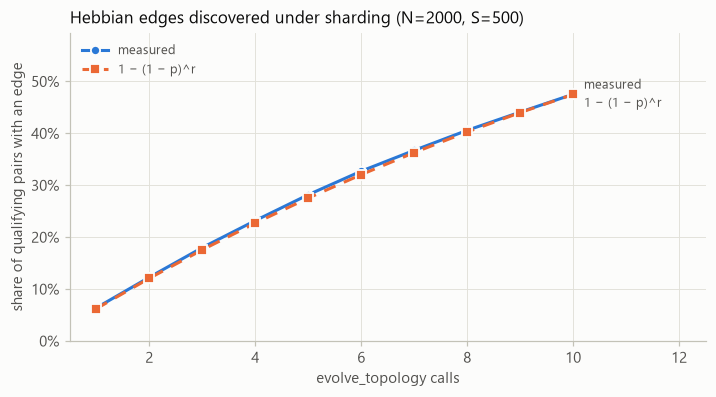

In [11]:
fig, ax = new_ax("Hebbian edges discovered under sharding (N=2000, S=500)", "evolve_topology calls",
                 "share of qualifying pairs with an edge")
plot_series(ax, rounds, coverage, 0, "measured", dy=6)
plot_series(ax, rounds, theory, 1, "1 − (1 − p)^r", linestyle=(0, (4, 3)), dy=-6)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, max(coverage + theory) * 1.25)
ax.set_xlim(0.5, 12.5)
finish(fig, ax, legend_loc="upper left")

Discovery follows the shard lottery: about 6 % of qualifying pairs per call, so even after ten calls
roughly half of the edges that should exist are missing. For large graphs, an approximate
nearest-neighbour search (e.g. FAISS) would find all of them at a fraction of the cost.

## 6 · Hebbian plasticity: co-firing over time, or a similarity threshold?

**Claim:** "edges that fire together wire together". **Test:** after one `evolve_topology` call,
compare the reported new/strengthened edges with the plain threshold graph
$\{(i,j) : \cos(x_i, x_j) \ge \theta\}$ computed on the returned states.

In [12]:
Xh, yh, Eh = csbm(n=600, h=0.8, noise=1.5, seed=4)
g = build_graph(Xh, Eh, threshold=0.65)
res = g.evolve_topology(1.0)
Z = node_states(g, len(yh))
Ssim = Z @ Z.T
iu = torch.triu_indices(len(yh), len(yh), 1)
thr_graph = {(int(a), int(b)) for a, b in iu.T[Ssim[iu[0], iu[1]] >= 0.65].tolist()}
existing = {tuple(sorted(e)) for e in Eh}
reported_new = {tuple(sorted((int(u[1:]), int(v[1:])))) for u, v, _ in res["new_edges"]}
reported_str = {tuple(sorted((int(u[1:]), int(v[1:])))) for u, v, _ in res["strengthened_edges"]}
print(f"new edges reported: {len(reported_new)}, threshold graph minus existing: {len(thr_graph - existing)}")
print(f"strengthened reported: {len(reported_str)}, threshold graph within existing: {len(thr_graph & existing)}")
assert reported_new == thr_graph - existing and reported_str == thr_graph & existing
print(f"edge homophily: original graph {edge_homophily(Eh, yh):.2f}, new 'Hebbian' edges {edge_homophily(list(reported_new), yh):.2f}")

new edges reported: 139, threshold graph minus existing: 139
strengthened reported: 17, threshold graph within existing: 17
edge homophily: original graph 0.80, new 'Hebbian' edges 1.00


The edge rule is exactly a cosine-similarity threshold on the current states, applied once per
call. There is no activity trace over time, so "similarity-driven edge growth" is the accurate
name. It is still useful: the new edges are far more class-consistent than the input graph.

## 7 · Does the filter help a downstream task? Baselines across homophily

Contextual stochastic block model, 900 nodes, 3 classes, 64-d noisy features, average degree 10,
edge homophily $h$ from 0.1 (edges mostly between classes) to 0.9 (mostly within; random = 0.33).
Compared on the same inputs:

* **raw features** (no graph),
* **LiquidGraph**, one `evolve_topology(1.0)` call with default parameters,
* **PPR / APPNP** with the common teleport 0.1 (closed form).

Metrics: purity@10 (share of a node's 10 nearest neighbours in its class) and k-means ARI.
Mean over 3 seeds.

In [13]:
H = [0.1, 0.2, 0.33, 0.5, 0.7, 0.9]
results = {name: {"purity": [], "ari": []} for name in ("raw", "lgnn", "ppr")}
for h in H:
    acc = {name: {"purity": [], "ari": []} for name in results}
    for seed in range(3):
        Xb, yb, Eb = csbm(n=900, h=h, seed=10 + seed)
        Ab = adjacency(len(yb), Eb)
        gb = build_graph(Xb, Eb)
        gb.evolve_topology(1.0)
        reps = {"raw": Xb, "lgnn": node_states(gb, len(yb)), "ppr": ppr_propagate(Xb, Ab, 0.1)}
        for name, R in reps.items():
            acc[name]["purity"].append(purity_at_k(R, yb))
            acc[name]["ari"].append(kmeans_ari(R, yb, seed=seed))
    for name in results:
        for metric in ("purity", "ari"):
            results[name][metric].append(float(np.mean(acc[name][metric])))

labels = {"raw": "raw features", "lgnn": "LiquidGraph (T=1)", "ppr": "PPR/APPNP (0.1)"}
print(f"{'h':>5} | " + " | ".join(f"{labels[n]:>18}" for n in results) + "   (purity@10 / ARI)")
for i, h in enumerate(H):
    print(f"{h:>5} | " + " | ".join(f"{results[n]['purity'][i]:>8.3f} / {results[n]['ari'][i]:>6.3f}" for n in results))

    h |       raw features |  LiquidGraph (T=1) |    PPR/APPNP (0.1)   (purity@10 / ARI)
  0.1 |    0.669 /  0.705 |    0.616 /  0.628 |    0.461 /  0.333
  0.2 |    0.669 /  0.705 |    0.636 /  0.667 |    0.513 /  0.447
 0.33 |    0.669 /  0.705 |    0.665 /  0.703 |    0.592 /  0.602
  0.5 |    0.669 /  0.705 |    0.703 /  0.750 |    0.738 /  0.766
  0.7 |    0.669 /  0.705 |    0.749 /  0.794 |    0.936 /  0.951
  0.9 |    0.669 /  0.705 |    0.799 /  0.866 |    0.999 /  0.997


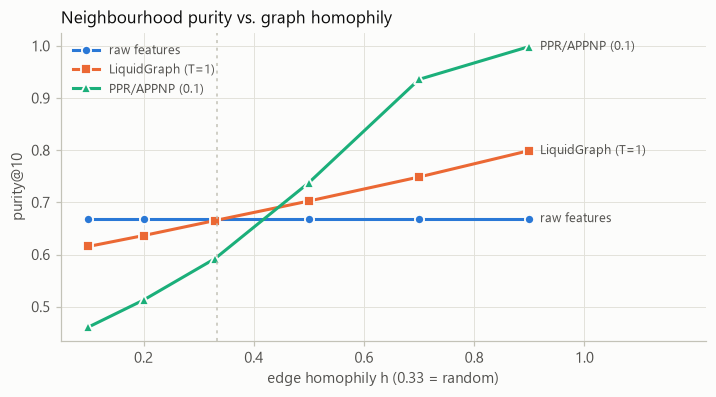

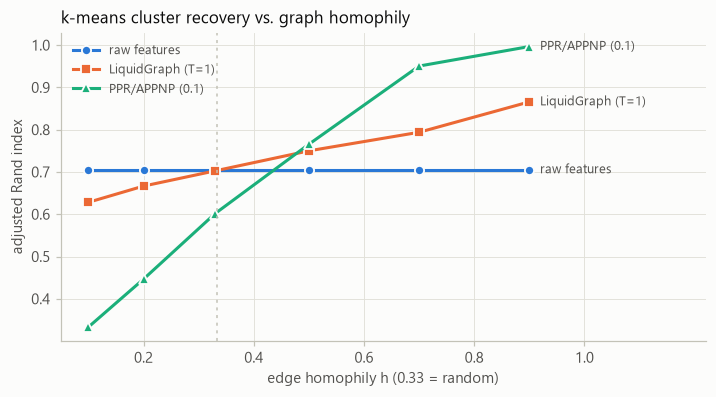

In [14]:
for metric, title, ylabel in (("purity", "Neighbourhood purity vs. graph homophily", "purity@10"),
                              ("ari", "k-means cluster recovery vs. graph homophily", "adjusted Rand index")):
    fig, ax = new_ax(title, "edge homophily h (0.33 = random)", ylabel)
    for slot, name in enumerate(("raw", "lgnn", "ppr")):
        plot_series(ax, H, results[name][metric], slot, labels[name])
    ax.axvline(1 / 3, color=AXIS, linewidth=1, linestyle=(0, (2, 3)))
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlim(0.05, 1.22)
    finish(fig, ax, legend_loc="upper left")

LiquidGraph behaves like the established propagation baseline it is mathematically equivalent to:
it helps when the graph agrees with the classes ($h$ above random), hurts when it does not, and its
strong anchor ($\gamma \approx 0.59$) makes it a *gentler* smoother than APPNP with teleport 0.1, so it
gains less on homophilous graphs and loses less on heterophilous ones. It is a sound, cheap feature
smoother, but not a new learning mechanism.

## 8 · Anchoring: does the elastic tether prevent collapse?

**Claim (code comment):** the Hookean tether "strictly preserves conceptual distinctness".
Pure diffusion ($\lambda = 0$) drives every connected component to its mean (over-smoothing).
**Test:** evolve for increasing `compute_time` with the default tether (0.5) and without it, and
track both how alike the states become (mean pairwise cosine) and how much class structure the
neighbourhoods keep (purity@10).

In [15]:
Xo, yo, Eo = csbm(n=600, h=0.8, seed=5)
Ts = [0.5, 1, 2, 4, 8, 16, 32, 64, 128]
smooth = {lam: {"cos": [], "purity": []} for lam in (0.5, 0.0)}
for lam in smooth:
    for T in Ts:
        go = build_graph(Xo, Eo, tether=lam)
        go.evolve_topology(compute_time=T)
        Zo = node_states(go, len(yo))
        smooth[lam]["cos"].append(mean_pairwise_cos(Zo))
        smooth[lam]["purity"].append(purity_at_k(Zo, yo))
print(f"raw: mean pairwise cos {mean_pairwise_cos(Xo):.3f}, purity@10 {purity_at_k(Xo, yo):.3f}")
print(f"{'T':>5} | {'tether 0.5: cos / purity':>26} | {'no tether: cos / purity':>25}")
for i, T in enumerate(Ts):
    print(f"{T:>5} | {smooth[0.5]['cos'][i]:>12.3f} / {smooth[0.5]['purity'][i]:<11.3f} | "
          f"{smooth[0.0]['cos'][i]:>11.3f} / {smooth[0.0]['purity'][i]:<11.3f}")

raw: mean pairwise cos 0.024, purity@10 0.666
    T |   tether 0.5: cos / purity |   no tether: cos / purity
  0.5 |        0.032 / 0.727       |       0.033 / 0.735      
    1 |        0.039 / 0.773       |       0.045 / 0.804      
    2 |        0.050 / 0.825       |       0.078 / 0.920      
    4 |        0.058 / 0.855       |       0.185 / 0.983      
    8 |        0.061 / 0.858       |       0.485 / 0.993      
   16 |        0.061 / 0.858       |       0.840 / 0.987      
   32 |        0.061 / 0.858       |       0.985 / 0.980      
   64 |        0.061 / 0.858       |       1.000 / 0.978      
  128 |        0.061 / 0.858       |       1.000 / 0.381      


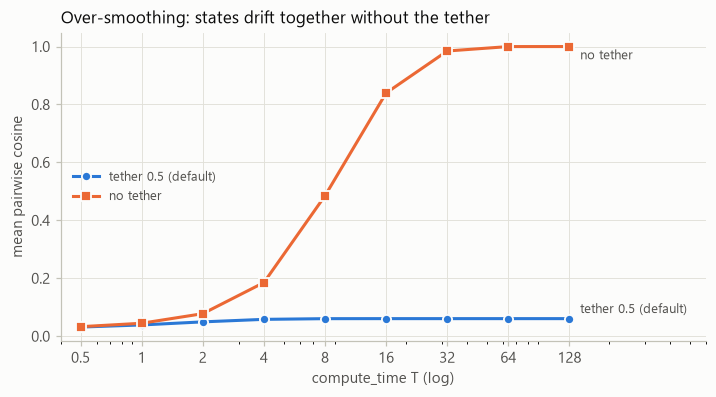

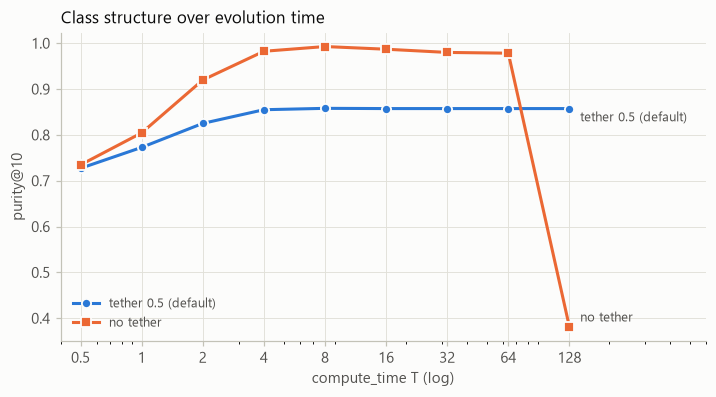

In [16]:
for metric, title, ylabel in (("cos", "Over-smoothing: states drift together without the tether", "mean pairwise cosine"),
                              ("purity", "Class structure over evolution time", "purity@10")):
    fig, ax = new_ax(title, "compute_time T (log)", ylabel)
    ax.set_xscale("log")
    plot_series(ax, Ts, smooth[0.5][metric], 0, "tether 0.5 (default)", dy=6 if metric == "cos" else -6)
    plot_series(ax, Ts, smooth[0.0][metric], 1, "no tether", dy=-6 if metric == "cos" else 6)
    ax.set_xticks(Ts, [str(t) for t in Ts])
    ax.set_xlim(0.4, 600)
    finish(fig, ax, legend_loc="center left" if metric == "cos" else "lower left")

**Distinctness: confirmed.** With the tether, states converge to the PPR fixed point from section 1
and stay almost as different from each other as the inputs, for any `compute_time`. Without it,
the states visibly collapse towards one vector.

**But the tether is not what preserves class structure here, and that part of the intuition is
refuted.** Unanchored diffusion reaches much higher purity: the slowest-decaying directions of the
diffusion are the graph's communities (the same effect spectral clustering uses), so relative
differences between classes survive long after absolute differences shrink. The price is numerical:
the class signal ends up in ever smaller differences between nearly identical unit vectors, so
results get fragile and eventually drop at long times.

So the tether is a trade-off knob between "keep each concept close to its original meaning" and
"let the graph reorganise it". With $\lambda = 0.5$ against a diffusion rate of $0.35$ it sits far
on the conservative side; making both rates configurable (or learnable) would let users choose.

## Conclusions and next steps

**What holds up**

* A well-defined, numerically stable propagation scheme. With the tether it behaves like Personalized PageRank
  propagation, which is a strong and well-understood baseline in graph learning.
* The tether is a real, useful knob against over-smoothing.
* Similarity-driven edge growth adds class-consistent edges, which is valuable for densifying a knowledge graph.

**Suggested next steps, roughly in order of effort**

1. **Memory:** run the solve under `torch.no_grad()` and keep the adjacency sparse (separate PR). Same results,
   ~10× less memory, ODE cost proportional to the number of edges.
2. **Honest README:** describe the actual model ($\dot x = \alpha(D^{-1}A - I)x - \lambda(x - x_0)$), cite
   PPR/APPNP and graph diffusion, and drop "O(1) RAM" and "Hebbian co-firing" unless they get implemented.
3. **Dead weight:** remove `flow_dynamics` / `resonance_aligner` (keeping old checkpoints loadable) or wire them in.
4. **Metrics:** replace "energy" with something informative, e.g. the tether strain or per-call movement that the
   code already computes.
5. **Expose the knobs:** the diffusion rate 0.35 is hard-coded; make it a parameter next to `tether_strength`
   and choose both on validation data (section 7 shows the default is conservative).
6. **Edge discovery at scale:** replace random shards with approximate nearest-neighbour search (FAISS, hnswlib).
7. **If "liquid" is the goal:** implement liquid time-constant / closed-form continuous-time dynamics with learnable
   $\tau$ and inputs, and train them. Section 1 of this notebook should then *fail* — that is the point of having it.

Extending the evidence: the same experiments can run on real citation graphs (Cora, CiteSeer, PubMed via
PyTorch Geometric) to check that the synthetic results carry over.

**References**

* J. Gasteiger, A. Bojchevski, S. Günnemann. *Predict then Propagate: Graph Neural Networks meet Personalized PageRank.* ICLR 2019. [arXiv:1810.05997](https://arxiv.org/abs/1810.05997)
* J. Gasteiger, S. Weißenberger, S. Günnemann. *Diffusion Improves Graph Learning.* NeurIPS 2019. [arXiv:1911.05485](https://arxiv.org/abs/1911.05485)
* Y. Deshpande, S. Sen, A. Montanari, E. Mossel. *Contextual Stochastic Block Models.* NeurIPS 2018. [arXiv:1807.09596](https://arxiv.org/abs/1807.09596)
* Q. Li, Z. Han, X.-M. Wu. *Deeper Insights into Graph Convolutional Networks for Semi-Supervised Learning* (over-smoothing). AAAI 2018. [arXiv:1801.07606](https://arxiv.org/abs/1801.07606)
* R. Hasani et al. *Liquid Time-constant Networks.* AAAI 2021. [arXiv:2006.04439](https://arxiv.org/abs/2006.04439)
* R. Hasani et al. *Closed-form Continuous-time Neural Networks.* Nature Machine Intelligence 2022. [arXiv:2106.13898](https://arxiv.org/abs/2106.13898)